# Which letters does the model mix up?

Sema's letter model reads a hand and says which of the 24 still letters (A to Y, without J)
it makes. This notebook asks two questions about it:

1. **How often is each letter right?**
2. **When it is wrong, which letter does it say instead?** That is a *confusion matrix*.

**Why 24 letters, not 26?** J and Z are left out on purpose. They are drawn in the air, so one
frame can't show them. Sema traces them on Learn instead of classifying them, so the model has
no J or Z to say.

**The test.** The public photos (ASL-HG and ASLYset) hold 14 different signers. The test trains
on 13 of them and reads the 14th, in turn, so every photo is read by a model that never saw
that person. This is `leave_one_signer_out`, the same test `train_small.py` uses to judge the
model. It reuses the code in `training/`, so it follows the same rules.

**Needs:** the extracted files in `data/extracted/` (made at `/dev/extract`). They are public
data, so nothing private is used here.

## 1. Setup

The `training/` scripts import each other by plain name (`from knn import vote`), so this cell adds that folder to Python's search path.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

# A notebook starts in its own folder (training/notebooks), so go up until we find the project.
ROOT = Path.cwd()
while not (ROOT / "training").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "training"))

from dataset import STATIC_LETTERS, clean, load_inputs, photo_samples
from evaluate import mean_share, mistakes, share_right
from small import leave_one_signer_out, make_logistic

PHOTOS = sorted((ROOT / "data" / "extracted").glob("*.json"))
print("Files:", ", ".join(p.name for p in PHOTOS))

Files: sema-extracted-asl-hg-2026-10-22.json, sema-extracted-aslyset-2026-10-22.json


## 2. Load and clean the photos

Each sample holds the 63 numbers of a normalized hand (the same ones the browser feeds the
model), the letter, and the `person` who signed it. `clean` drops photos that can't be learned
from (two hands, a hand cut off by the photo's edge, a broken detection).

In [2]:
extracted, _ = load_inputs([str(p) for p in PHOTOS])
photos, _ = clean(photo_samples(extracted))

shapes = np.array([s["landmarks"] for s in photos])
true = [s["letter"] for s in photos]
people = [s["person"] for s in photos]
print(f"{len(photos):,} photos of {len(set(true))} letters, from {len(set(people))} signers")

27,463 photos of 24 letters, from 14 signers


## 3. Read every photo with a model that never saw its signer

`make_logistic(1)` is the live model's kind: logistic regression with C = 1. (If
`train_small.py` picks another setting one day, change it here too.) It trains 14 models, so
this cell takes a minute or two.

In [3]:
predicted, _ = leave_one_signer_out(lambda: make_logistic(1), shapes, true, people)

by_letter = share_right(true, predicted)
print(f"Mean of the letters: {mean_share(by_letter):.1%}")

Mean of the letters: 94.5%


## 4. How often is each letter right?

Every letter counts the same however many photos it has, so the mean is the mean of the
letters' shares (`mean_share`). Blue bars reach 90%, amber ones don't.

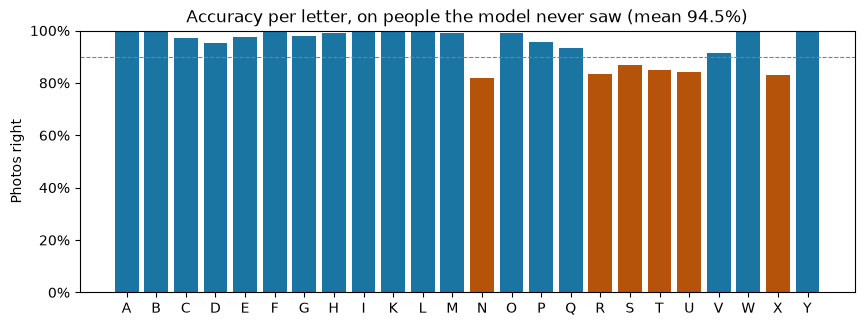

Weakest: N 82%, X 83%, R 84%, U 84%, T 85%


In [4]:
letters = STATIC_LETTERS
shares = [by_letter[l][0] / by_letter[l][1] for l in letters]

fig, ax = plt.subplots(figsize=(10, 3.4))
ax.bar(letters, shares, color=["#1A75A3" if s >= 0.9 else "#B45309" for s in shares])
ax.set_ylim(0, 1)
ax.set_ylabel("Photos right")
ax.set_title(f"Accuracy per letter, on people the model never saw (mean {mean_share(by_letter):.1%})")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.axhline(0.9, color="grey", linewidth=0.8, linestyle="--")
plt.show()

weakest = sorted(letters, key=lambda l: by_letter[l][0] / by_letter[l][1])[:5]
print("Weakest:", ", ".join(f"{l} {by_letter[l][0] / by_letter[l][1]:.0%}" for l in weakest))

## 5. The confusion matrix

Each **row** is the letter that was really signed; each **column** is what the model said.
A perfect model would fill only the diagonal. Each row adds to 100%, so a bright square off
the diagonal means "when this letter is signed, the model often says *that* one instead".
Squares under 3% are left unlabelled so the chart stays readable.

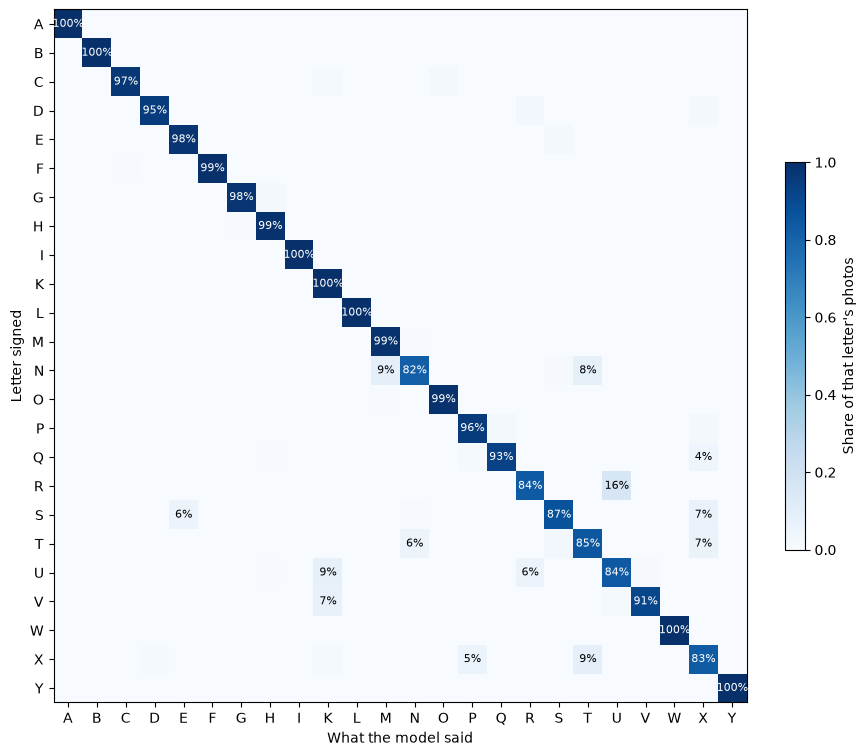

In [5]:
counts = np.zeros((len(letters), len(letters)))
for t, p in zip(true, predicted):
    counts[letters.index(t), letters.index(p)] += 1
matrix = counts / counts.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(10, 9))
image = ax.imshow(matrix, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(letters)), letters)
ax.set_yticks(range(len(letters)), letters)
ax.set_xlabel("What the model said")
ax.set_ylabel("Letter signed")
for i in range(len(letters)):
    for j in range(len(letters)):
        if matrix[i, j] >= 0.03:
            color = "white" if matrix[i, j] > 0.5 else "black"
            ax.text(j, i, f"{matrix[i, j]:.0%}", ha="center", va="center", fontsize=8, color=color)
fig.colorbar(image, ax=ax, label="Share of that letter's photos", fraction=0.025)
plt.show()

## 6. The most common mistakes, in words

`mistakes` from `evaluate.py` lists (signed, said, how many photos, share of that letter), most common first.

In [6]:
for signed, said, n, share in mistakes(true, predicted)[:10]:
    print(f"{signed} read as {said}: {n:,} photos ({share:.0%} of the {signed}s)")

R read as U: 181 photos (16% of the Rs)
N read as M: 105 photos (9% of the Ns)
X read as T: 100 photos (9% of the Xs)
N read as T: 99 photos (8% of the Ns)
U read as K: 96 photos (9% of the Us)
V read as K: 83 photos (7% of the Vs)
S read as X: 80 photos (7% of the Ss)
T read as X: 79 photos (7% of the Ts)
S read as E: 68 photos (6% of the Ss)
T read as N: 66 photos (6% of the Ts)


## What to do with this

- A letter with an amber bar in section 4 is one to look at first (check its finger conditions in
  `letterShapes.js`, or look at its photos).
- A bright off-diagonal square in section 5 names a *pair* of letters whose hand shapes are
  close. Compare their drawings to see why.
- Lanix's own recordings (`data/raw/`) are a separate test and stay out of this notebook
  (`training/README.md`, "Data rules").